# Modern Python 3.12–3.14

Python releases a new version every October. Many tutorials still show code in the style of Python 3.6. This lesson shows the features of recent versions that change how you write and run Python.

**After this lesson you can:**

1. Use structural pattern matching (`match`) with sequences, dicts and classes.
2. Use the new syntax of 3.11–3.12: generics, `type` aliases, f-strings, `tomllib`, `itertools.batched`.
3. Explain the free-threaded build (no GIL) and measure its effect.
4. Recognise the main 3.14 features: template strings and deferred annotations.

This notebook runs Python 3.12. The sections on 3.13 and 3.14 run small scripts with interpreters that **uv** installs for free (`uv python install 3.13t 3.14`).

## 1. Structural Pattern Matching (3.10+)

`match` compares a value against **patterns**. A pattern can check the shape of the value and extract parts of it into variables at the same time.

| Pattern | Matches |
| :--- | :--- |
| `case 200:` | a literal value |
| `case [x, y]:` | a sequence of length 2; binds `x`, `y` |
| `case {"type": "click", "x": x}:` | a dict with these keys (extra keys are allowed) |
| `case Point(x=0, y=y):` | an object of class `Point` with `x == 0` |
| `case _ if cond:` | anything, with a guard condition |

In [1]:
from dataclasses import dataclass

@dataclass
class Point:
    x: float
    y: float

def handle(event):
    match event:
        case {"type": "click", "pos": [x, y]}:
            return f"click at ({x}, {y})"
        case {"type": "key", "key": "q" | "Q"}:
            return "quit"
        case {"type": "key", "key": str(k)}:
            return f"key {k!r}"
        case Point(x=0, y=0):
            return "origin"
        case Point(x=0, y=y):
            return f"on the y-axis at {y}"
        case [first, *rest] if len(rest) > 2:
            return f"long list starting with {first}"
        case _:
            return "unknown event"

events = [{"type": "click", "pos": [10, 20]}, {"type": "key", "key": "Q"}, {"type": "key", "key": "a"},
          Point(0, 0), Point(0, 5), [1, 2, 3, 4], 42]
for e in events:
    print(f"{e!r:<38} -> {handle(e)}")

{'type': 'click', 'pos': [10, 20]}     -> click at (10, 20)
{'type': 'key', 'key': 'Q'}            -> quit
{'type': 'key', 'key': 'a'}            -> key 'a'
Point(x=0, y=0)                        -> origin
Point(x=0, y=5)                        -> on the y-axis at 5
[1, 2, 3, 4]                           -> long list starting with 1
42                                     -> unknown event


## 2. Smaller Improvements of 3.11 and 3.12

| Version | Feature |
| :--- | :--- |
| 3.11 | 10–60% faster interpreter; `ExceptionGroup` / `except*`; `tomllib` reads TOML files; better error messages with exact positions |
| 3.12 | type parameter syntax `def f[T]()` and `type` aliases (Lesson 16); f-strings can reuse the same quotes and contain comments; `itertools.batched`; per-interpreter GIL (internal) |
| 3.13 | experimental free-threaded build (no GIL); experimental JIT compiler; a new interactive shell with colours and multi-line editing |
| 3.14 | template strings (`t"..."`); deferred evaluation of annotations; free-threading is officially supported; `compression.zstd`; multiple interpreters in the standard library |

In [2]:
import itertools
import tomllib

songs = ["Intro", "Bad Day", "Wonderwall", "Yesterday", "Imagine"]
print(f"Playlist: {', '.join(f"{s!r}" for s in songs)}")        # 3.12: same quotes inside an f-string

for batch in itertools.batched(range(10), 4):                     # 3.12
    print("batch:", batch)

config = tomllib.loads("""
[model]
name = "gpt2"
max_tokens = 128
[training]
epochs = 3
lr = 3e-4
""")
print("TOML:", config)

Playlist: 'Intro', 'Bad Day', 'Wonderwall', 'Yesterday', 'Imagine'
batch: (0, 1, 2, 3)
batch: (4, 5, 6, 7)
batch: (8, 9)
TOML: {'model': {'name': 'gpt2', 'max_tokens': 128}, 'training': {'epochs': 3, 'lr': 0.0003}}


## 3. Free-Threaded Python (3.13t): Python Without the GIL

The **Global Interpreter Lock (GIL)** lets only one thread run Python bytecode at a time. Lesson 17 showed the result: threads do not speed up CPU-bound Python code. Python 3.13 ships an optional **free-threaded build** (`python3.13t`) without the GIL. In 3.14 this build is officially supported (PEP 779).

The experiment runs the same CPU-bound script with 1 and 4 threads in two interpreters:

1. Python 3.12 (normal build, with the GIL),
2. Python 3.13t (free-threaded build).

In [3]:
import shutil
import subprocess
import sys
import textwrap

bench = textwrap.dedent("""
    import sys, time
    from concurrent.futures import ThreadPoolExecutor
    def work(_):
        total = 0
        for i in range(3_000_000):
            total += i * i
        return total
    def run(workers):
        t = time.perf_counter()
        with ThreadPoolExecutor(workers) as ex:
            list(ex.map(work, range(4)))
        return time.perf_counter() - t
    gil = sys._is_gil_enabled() if hasattr(sys, "_is_gil_enabled") else True
    print(f"{sys.version.split()[0]} {gil} {run(1):.3f} {run(4):.3f}")
""")

def uv_python(version: str) -> str | None:
    uv = shutil.which("uv")
    if not uv:
        return None
    r = subprocess.run([uv, "python", "find", "--no-project", version], capture_output=True, text=True)
    return r.stdout.strip() or None

interpreters = {"3.12 (GIL)": sys.executable, "3.13t (free-threaded)": uv_python("3.13t")}
results = {}
for label, exe in interpreters.items():
    if not exe:
        print(f"{label}: interpreter not found -> run `uv python install 3.13t`")
        continue
    out = subprocess.run([exe, "-c", bench], capture_output=True, text=True).stdout.split()
    version, gil, t1, t4 = out[0], out[1], float(out[2]), float(out[3])
    results[label] = (t1, t4)
    print(f"{label:<22} Python {version:<8} GIL enabled: {gil:<5} 1 thread {t1:5.2f} s | 4 threads {t4:5.2f} s "
          f"| speed-up {t1 / t4:.2f}x")

3.12 (GIL)             Python 3.12.16  GIL enabled: True  1 thread  0.60 s | 4 threads  0.57 s | speed-up 1.05x


3.13t (free-threaded)  Python 3.13.18  GIL enabled: False 1 thread  0.78 s | 4 threads  0.34 s | speed-up 2.31x


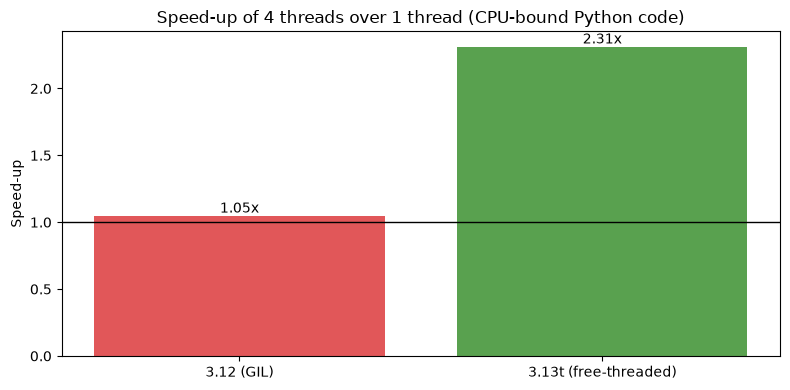

In [4]:
import matplotlib.pyplot as plt

if results:
    fig, ax = plt.subplots(figsize=(8, 4))
    labels = list(results)
    speedups = [t1 / t4 for t1, t4 in results.values()]
    bars = ax.bar(labels, speedups, color=["#E15759", "#59A14F"][:len(labels)])
    ax.axhline(1, color="black", lw=1)
    for b, s in zip(bars, speedups):
        ax.text(b.get_x() + b.get_width() / 2, s, f"{s:.2f}x", ha="center", va="bottom")
    ax.set(title="Speed-up of 4 threads over 1 thread (CPU-bound Python code)", ylabel="Speed-up")
    plt.tight_layout()
    plt.show()

With the GIL, 4 threads are not faster than 1 thread. Without the GIL, the 4 threads run on several CPU cores at the same time. The single-thread time of the free-threaded build can be a little higher: the interpreter does extra work to stay thread-safe.

**Caution:** many C extensions (NumPy, pandas, PyTorch) added free-threading support only recently. Check that your libraries support the build before you use it in production.

## 4. Python 3.14: Template Strings and Deferred Annotations

- **Template strings** (`t"..."`, PEP 750) look like f-strings, but they do not produce a string. They produce a `Template` object that keeps the static text and the interpolated values separate. A library can then process the values safely, for example escape HTML or build a parameterised SQL query. This prevents injection attacks.
- **Deferred annotations** (PEP 649): annotations are evaluated only when something reads them. Forward references (a class that refers to itself) work without quotes.

The cell runs a short 3.14 script.

In [5]:
script314 = textwrap.dedent("""
    from string.templatelib import Template, Interpolation
    import html

    def safe_html(template: Template) -> str:
        parts = []
        for item in template:
            if isinstance(item, Interpolation):
                parts.append(html.escape(str(item.value)))   # escape only the user values
            else:
                parts.append(item)                              # static text stays as written
        return "".join(parts)

    user = "<script>alert('x')</script>"
    t = t"<p>Hello, {user}!</p>"
    print("type   :", type(t).__name__)
    print("strings:", t.strings)
    print("values :", t.values)
    print("safe   :", safe_html(t))

    class Node:
        def link(self, other: Node) -> Node:      # no quotes needed: deferred annotations
            return other
    print("deferred annotation:", Node.link.__annotations__)
""")
exe314 = uv_python("3.14")
if exe314:
    r = subprocess.run([exe314, "-c", script314], capture_output=True, text=True)
    print(r.stdout or r.stderr)
else:
    print("Python 3.14 not found -> run `uv python install 3.14`")

type   : Template
strings: ('<p>Hello, ', '!</p>')
values : ("<script>alert('x')</script>",)
safe   : <p>Hello, &lt;script&gt;alert(&#x27;x&#x27;)&lt;/script&gt;!</p>
deferred annotation: {'other': <class '__main__.Node'>, 'return': <class '__main__.Node'>}



The user value contained an HTML `<script>` tag. The template kept it separate from the static text, so `safe_html()` escaped only the value. An f-string would have mixed both into one string, and the tag would reach the browser.

*Insight: Write new code for a supported Python version (3.12 or newer) and use its features: pattern matching for structured data, the short generic syntax, and `tomllib`. Watch free-threading: it removes the main limit of Python for CPU-bound multi-threaded code.*

## Real-World Use Case or Analogy

Pattern matching is like **a sorting office that reads the shape of each parcel**: letters go to one belt, small boxes to another, and boxes with a "fragile" label to a third. One look at the shape both selects the belt and reads the address.

Free-threading is like **opening more checkout lanes in a supermarket** that had only one cashier allowed to work at a time. The building could always hold more cashiers; the rule (the GIL) prevented it. Web servers, data loaders for machine learning and LLM inference servers are expected to benefit most, because they run many threads that compute at the same time.